# Ames Housing — Modelado v2: ingeniería de características avanzada, outliers, stacking y ajuste de hiperparámetros

## Objetivo

Mejorar el notebook de modelado original (`LinearRegression`, `RandomForest`, `GradientBoosting`) **sin sobreajustar y sin fuga de datos (data leakage)**, partiendo de las decisiones del EDA y de la metadata (`data_description.txt`).

## Qué cambia respecto de la versión 1

| Tema | Versión 1 | Versión 2 (este notebook) | Por qué mejora |
|---|---|---|---|
| **Outliers** | Se conservaban en el entrenamiento | Se eliminan **solo en Training** (casas con `GrLivArea > 4000` y `SalePrice < 300000`) con una regla fija y documentada | Esas ventas parciales confunden a los modelos: enseñan que "más metros = más barato" |
| **Asimetría** | `log1p` fijo en una lista de columnas | **Box-Cox** con λ estimado *dentro de cada fold* y solo en columnas realmente sesgadas | Cada variable recibe la potencia que mejor la acerca a una normal; el umbral de asimetría es un hiperparámetro |
| **Features** | Superficies, baños, edades | + calidad compuesta, interacciones calidad×superficie, ratios, edad del garage, `IsNew`, categorías raras agrupadas, columnas casi constantes descartadas | Más señal con menos ruido |
| **Modelos** | Linear, RF, GBR | **ElasticNet**, Random Forest, Gradient Boosting + **Stacking** + **Voting** (solo modelos clásicos de scikit-learn) | Modelos lineales regularizados y de árboles cometen errores distintos; combinarlos los compensa |
| **Hiperparámetros** | Grillas discretas chicas | Búsqueda aleatoria con distribuciones continuas, CV de 5 folds, con regularización fuerte | Explora mejor el espacio sin tocar Validation |
| **Selección del mejor** | Por RMSE en Validation | Por RMSE de **cross-validation en Training**; Validation solo se usa para reportar | Elegir con Validation filtra información de Validation hacia la decisión |
| **Métricas** | MAE y RMSE en USD | RMSE y MAE en **USD y en %**, RMSPE, MAPE y R², con interpretación | Un error de USD 20.000 pesa distinto en una casa de USD 80.000 que en una de USD 400.000 |

## Principios anti-leakage que se respetan en todo el notebook

1. **Validation no se toca hasta el final**: no participa en imputación, Box-Cox, escalado, categorías, selección de outliers, hiperparámetros ni elección del modelo.
2. **Todo lo que "aprende" algo de los datos vive dentro de un `Pipeline`**, de modo que en cada fold se ajusta solo con la parte de entrenamiento de ese fold.
3. **Los outliers se eliminan con una regla fija** (umbrales del EDA), no con estadísticos calculados sobre todo el dataset, y **solo del conjunto de entrenamiento**. Validation conserva sus filas tal como llegan: así la evaluación refleja datos reales.
4. El **stacking** usa predicciones *out-of-fold* para entrenar el meta-modelo (`StackingRegressor` lo hace internamente).
5. Se incluyen **verificaciones ejecutables** de leakage (sección 14).

## 1. Configuración e imports

Se fija una semilla global y se centralizan rutas y presupuestos de búsqueda (`N_ITER`). Para una corrida rápida de prueba se puede reducir `N_ITER`.

Todos los modelos son clásicos de scikit-learn; solo se usa SciPy (para Box-Cox) además de las librerías habituales. La celda siguiente instala lo necesario si falta.

In [8]:
%pip install -q scikit-learn scipy pandas numpy matplotlib joblib


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
from scipy.special import boxcox1p
from scipy.stats import loguniform, randint, uniform

from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
    VotingRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ["PYTHONWARNINGS"] = "ignore"   # también silencia los procesos paralelos de las búsquedas

RANDOM_STATE = 42
N_SPLITS = 5
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Presupuesto de combinaciones por búsqueda. Subir si hay más tiempo de cómputo.
N_ITER = {"ElasticNet": 60, "RandomForest": 20, "GradientBoosting": 30}

# Rutas candidatas: el notebook usa la primera carpeta que contenga ambos CSV.
CANDIDATE_DIRS = [
    Path("../ames-housing-desarrollo-estudiantes"),
    Path("ames-housing-desarrollo-estudiantes"),
    Path("."),
    Path("data"),
]
DATA_DIR = next(
    (d for d in CANDIDATE_DIRS if (d / "train.csv").exists() and (d / "validation.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "No se encontraron train.csv y validation.csv. Agregá tu ubicación a CANDIDATE_DIRS."
    )

# Resultado de la versión 1 (mismos CSV) para medir la mejora. Es solo una referencia.
V1_REFERENCE = {"model": "Random Forest (v1)", "RMSE_USD": 28600.58, "MAE_USD": 17248.96}

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")
print("Carpeta de datos:", DATA_DIR.resolve())
print("Training:", train_df.shape, "| Validation:", val_df.shape)

Carpeta de datos: /Users/luciaolivera/caso1_ia/ames-housing-desarrollo-estudiantes
Training: (1022, 81) | Validation: (219, 81)


## 2. Auditoría inicial de los datos

Antes de modelar se verifican condiciones básicas que, si fallan, invalidan cualquier resultado:

- `SalePrice` existe y es positivo (necesario para `log1p`).
- Ningún `Id` aparece en Training **y** en Validation.
- No hay viviendas duplicadas entre Training y Validation (un duplicado sería una fuga disfrazada: el modelo "ya vio" la respuesta).

In [10]:
TARGET = "SalePrice"

assert TARGET in train_df.columns and TARGET in val_df.columns, "Falta SalePrice."
assert (train_df[TARGET] > 0).all() and (val_df[TARGET] > 0).all(), "SalePrice debe ser > 0."

if "Id" in train_df.columns and "Id" in val_df.columns:
    overlap_ids = set(train_df["Id"]) & set(val_df["Id"])
    assert not overlap_ids, f"Hay {len(overlap_ids)} Id en ambos conjuntos."

feature_cols = [c for c in train_df.columns if c not in ("Id", TARGET)]


def row_keys(df):
    """Una clave de texto por vivienda. Evita que falle la comparación si una columna tiene
    tipos distintos en cada archivo (p. ej. PoolQC totalmente vacía en uno y con texto en el otro)."""
    frame = df[feature_cols].copy()
    for c in feature_cols:
        frame[c] = (frame[c].astype(float) if pd.api.types.is_numeric_dtype(frame[c]) else frame[c]).astype(str)
    return set(frame.itertuples(index=False, name=None))


dups = row_keys(train_df) & row_keys(val_df)
print(f"Viviendas idénticas (en todas sus características) entre Training y Validation: {len(dups)}")
print("Faltantes totales en Training:", int(train_df.isna().sum().sum()))

Viviendas idénticas (en todas sus características) entre Training y Validation: 0
Faltantes totales en Training: 5429


**Cómo leer este resultado:** `0` duplicados y ningún `Id` compartido significa que Validation es un conjunto realmente independiente. Los faltantes no son un error: en Ames Housing la mayoría son `NA` con significado (sin pileta, sin garage, sin sótano), tal como indica la metadata y como ya detectó el EDA; se tratan en la sección 5.

## 3. Outliers: casas muy baratas para su metraje

El EDA identificó viviendas con `GrLivArea > 4000` pies² y `SalePrice < 300000`. La metadata aclara qué son: en `SaleCondition`, **`Partial` = "vivienda no terminada cuando fue tasada"** (asociada a casas nuevas). Es decir, se vendió una casa enorme *a medio construir*, y el precio no refleja el metraje final. Para el modelo son ruido: contradicen la relación "más superficie → más precio" que gobierna el resto de los datos.

**Decisión (y por qué es segura frente al leakage):**

- La regla usa **umbrales fijos** surgidos del EDA, no estadísticos recalculados con todos los datos.
- Se aplica **solo a Training**. En Validation *no* se eliminan filas: si lo hiciéramos, las métricas se verían mejor de lo que serían en producción, donde estas ventas también ocurren.
- La regla usa `SalePrice` para decidir qué filas descartar, algo permitido **únicamente en Training** (en producción no se conoce el precio de lo que se va a predecir; por eso nunca se usa para filtrar Validation).

Outliers en Training: 2 | en Validation (se conservan): 0
Precio mediano por pie² en Training: USD 120


,Id,GrLivArea,OverallQual,SaleCondition,SalePrice,USD_por_pie2
450,100365,5642,10,Partial,160000,28.358738
820,100219,4676,10,Partial,184750,39.510265


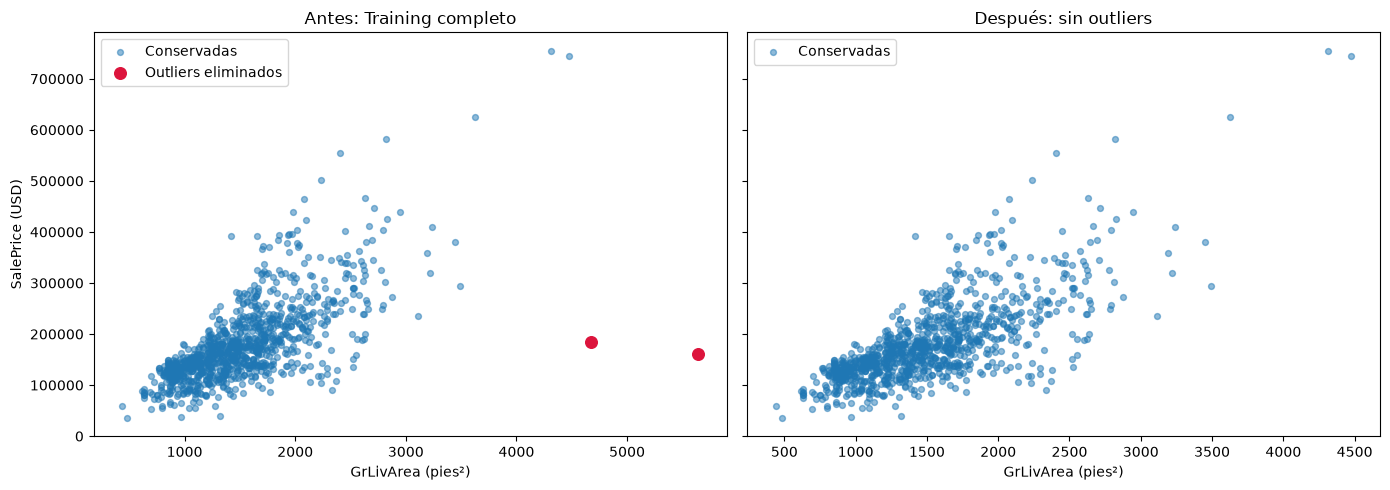

Training limpio: (1020, 81)


In [11]:
OUTLIER_GRLIVAREA_MIN = 4000      # pies²
OUTLIER_PRICE_MAX = 300_000       # USD


def price_outlier_mask(df):
    """Casas enormes vendidas muy por debajo de lo esperado para su superficie."""
    return (df["GrLivArea"] > OUTLIER_GRLIVAREA_MIN) & (df[TARGET] < OUTLIER_PRICE_MAX)


train_outliers = price_outlier_mask(train_df)
val_outliers = price_outlier_mask(val_df)

cols_show = [c for c in ["Id", "GrLivArea", "OverallQual", "SaleCondition", TARGET] if c in train_df.columns]
detail = train_df.loc[train_outliers, cols_show].copy()
detail["USD_por_pie2"] = detail[TARGET] / detail["GrLivArea"]
median_ppsf = (train_df[TARGET] / train_df["GrLivArea"]).median()
print(f"Outliers en Training: {int(train_outliers.sum())} | en Validation (se conservan): {int(val_outliers.sum())}")
print(f"Precio mediano por pie² en Training: USD {median_ppsf:,.0f}")
display(detail)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, flag, title in [
    (axes[0], train_outliers, "Antes: Training completo"),
    (axes[1], pd.Series(False, index=train_df.index), "Después: sin outliers"),
]:
    keep = train_df.loc[~train_outliers]
    ax.scatter(keep["GrLivArea"], keep[TARGET], alpha=0.5, s=18, label="Conservadas")
    if title.startswith("Antes"):
        ax.scatter(train_df.loc[train_outliers, "GrLivArea"], train_df.loc[train_outliers, TARGET],
                   color="crimson", s=70, label="Outliers eliminados")
    ax.set_title(title); ax.set_xlabel("GrLivArea (pies²)"); ax.legend()
axes[0].set_ylabel("SalePrice (USD)")
plt.tight_layout(); plt.show()

# Conjunto de entrenamiento final: la regla se aplica SOLO acá.
train_clean = train_df.loc[~train_outliers].reset_index(drop=True)
print("Training limpio:", train_clean.shape)

**Cómo leer estos resultados:**

- La tabla muestra el precio por pie² de cada outlier: es una fracción del precio mediano del resto de las casas. Todas son `SaleCondition = Partial` si el EDA tiene razón.
- En el gráfico, los puntos rojos están en la esquina inferior derecha: muchísimo metraje, precio bajo. Un modelo lineal intenta "pasar cerca" de esos puntos y **dobla la pendiente** de toda la recta; un modelo de árboles crea hojas exclusivas para ellos. En ambos casos se pierde precisión en las casas normales.
- Si en Validation aparecen casas que cumplen la regla, **no se eliminan**: serán parte del error final y lo reportaremos de forma transparente.

## 4. Variable objetivo y métricas

### Variable objetivo
`SalePrice` es asimétrica a la derecha (EDA). Se modela `log1p(SalePrice)`: los errores pasan a ser **relativos** (equivocarse 10 % cuesta lo mismo en una casa barata que en una cara) y los residuos se parecen más a una normal, que es lo que los modelos lineales suponen. Es una transformación determinista: no aprende nada de los datos, así que no hay leakage.

Como verificación descriptiva, el λ de Box-Cox que mejor normaliza el precio en Training debería estar cerca de 0 (que equivale al logaritmo).

### Métricas (todas se calculan en dólares, después de `expm1`)

| Métrica | Qué significa | Cómo interpretarla |
|---|---|---|
| **RMSE (USD)** | Raíz del error cuadrático medio | "Error típico" en dólares; **penaliza mucho los errores grandes**, por eso suele ser mayor que el MAE |
| **RMSE (% del precio medio)** | RMSE / precio medio de las casas | Escala el error al tamaño del mercado: permite comparar entre datasets o épocas |
| **RMSPE (%)** | Raíz del error cuadrático medio *porcentual por casa* | Error relativo típico de cada casa: un error de USD 20.000 es 10 % en una casa de 200.000 y 25 % en una de 80.000 |
| **MAE (USD)** | Error absoluto medio | Cuánto se equivoca el modelo *en promedio*, sin exagerar los casos grandes |
| **MAPE (%)** | Error absoluto porcentual medio | Lo mismo en términos relativos; más intuitivo para comunicar |
| **R²** | Proporción de la variabilidad del precio que el modelo explica | 1 = perfecto, 0 = no mejora a predecir la media |

In [12]:
def to_dollars(log_values):
    """Invierte log1p. La transformación del target es determinista (sin aprendizaje)."""
    return np.expm1(np.asarray(log_values, dtype=float))


def regression_report(y_true_usd, y_pred_usd):
    """Métricas en USD y en porcentaje."""
    y_true = np.asarray(y_true_usd, dtype=float)
    y_pred = np.asarray(y_pred_usd, dtype=float)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    rel = (y_true - y_pred) / y_true
    return {
        "RMSE_USD": rmse,
        "RMSE_%_del_precio_medio": 100 * rmse / y_true.mean(),
        "RMSPE_%": 100 * float(np.sqrt(np.mean(rel ** 2))),
        "MAE_USD": float(mean_absolute_error(y_true, y_pred)),
        "MAPE_%": 100 * float(np.mean(np.abs(rel))),
        "R2": float(r2_score(y_true, y_pred)),
    }


def rmse_usd_from_log(y_true_log, y_pred_log):
    return float(np.sqrt(mean_squared_error(to_dollars(y_true_log), to_dollars(y_pred_log))))


# Se calculan en cada fold de CV: RMSE en log (≈ error relativo) y RMSE en USD.
SCORING = {
    "rmse_log": "neg_root_mean_squared_error",
    "rmse_usd": make_scorer(rmse_usd_from_log, greater_is_better=False),
}

X_train = train_clean.drop(columns=[TARGET])
y_train = train_clean[TARGET]
y_train_log = np.log1p(y_train)

X_val = val_df.drop(columns=[TARGET])
y_val = val_df[TARGET]

lam_target = stats.boxcox_normmax(y_train.to_numpy(), method="mle")
print(f"λ de Box-Cox del precio (solo Training): {lam_target:.3f}  → cercano a 0 equivale a usar log")
print(f"Asimetría de SalePrice: {stats.skew(y_train):.2f}  →  log1p(SalePrice): {stats.skew(y_train_log):.2f}")

λ de Box-Cox del precio (solo Training): -0.079  → cercano a 0 equivale a usar log
Asimetría de SalePrice: 1.95  →  log1p(SalePrice): 0.12


**Cómo leer este resultado:** una asimetría de ~1.5–2 en dólares que baja a ~0 con `log1p` confirma que modelar el logaritmo es la decisión correcta; un λ cercano a 0 dice lo mismo desde Box-Cox. No usamos Box-Cox para el target (el logaritmo es más fácil de explicar y de invertir), pero sí para las variables predictoras, donde cada una necesita una potencia distinta.

## 5. Ingeniería de características (dentro de un transformer)

`AmesFeatureEngineer` hace tres cosas:

1. **Limpieza con significado** (metadata): `NA` en variables de sótano/garage/chimenea/etc. significa *"no tiene"* → categoría `"None"`; `MasVnrArea` ausente → 0; `MSSubClass` es un código, no una cantidad → texto.
2. **Estadísticos aprendidos en `fit`** (solo con la parte de entrenamiento de cada fold): mediana de `LotFrontage` por barrio, moda de `Electrical`, y columnas categóricas *casi constantes* (≥ 99 % en una sola categoría) que no aportan información.
3. **Variables nuevas**, todas calculadas fila por fila (determinísticas, sin mirar otras filas):

| Variable | Idea |
|---|---|
| `TotalSF`, `TotalBathrooms`, `TotalPorchSF` | Superficie y baños totales: el comprador piensa en el total |
| `HouseAgeAtSale`, `RemodAgeAtSale`, `GarageAgeAtSale`, `IsRemodeled`, `IsNew` | Antigüedad y renovación (recortadas a ≥ 0; el garage ausente hereda el año de la casa) |
| `QualityScore` | Suma de calidades (exterior, cocina, sótano, calefacción, garage, chimenea) |
| `QualxGrLivArea`, `QualxTotalSF`, `OverallQualSq` | Interacciones: un pie² de una casa de calidad 9 vale más que uno de calidad 4 |
| `LivLotRatio`, `AvgRoomSize` | Densidad de construcción sobre el terreno y tamaño medio de ambientes |
| `HasGarage`, `HasBsmt`, `HasFireplace`, `HasPool`, `Has2ndFloor`, `HasMasVnr` | Indicadores de existencia (efecto "tiene / no tiene") |

In [13]:
# ---- Codificación ordinal (de menor a mayor calidad). "None" = no existe la característica.
QUAL = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
BSMT_FIN = ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"]
ORDINAL_MAP = {
    "LotShape": ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope": ["Sev", "Mod", "Gtl"],
    "ExterQual": QUAL, "ExterCond": QUAL,
    "BsmtQual": QUAL, "BsmtCond": QUAL,
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": BSMT_FIN, "BsmtFinType2": BSMT_FIN,
    "HeatingQC": QUAL, "KitchenQual": QUAL, "FireplaceQu": QUAL,
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
    "GarageQual": QUAL, "GarageCond": QUAL,
    "PoolQC": ["None", "Fa", "TA", "Gd", "Ex"],
    "Functional": ["None", "Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "CentralAir": ["N", "Y"],
    "PavedDrive": ["N", "P", "Y"],
}
ORDINAL_FEATURES = list(ORDINAL_MAP)
ORDINAL_CATEGORIES = [ORDINAL_MAP[c] for c in ORDINAL_FEATURES]

missing_ordinals = [c for c in ORDINAL_FEATURES if c not in X_train.columns]
assert not missing_ordinals, f"Faltan columnas ordinales en los datos: {missing_ordinals}"

QUALITY_SCORE = {name: i for i, name in enumerate(QUAL)}
QUALITY_COLS = ["ExterQual", "KitchenQual", "BsmtQual", "HeatingQC", "GarageQual", "FireplaceQu"]

CATEGORICAL_ABSENCE = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType",
]


def is_numeric_col(series):
    return pd.api.types.is_numeric_dtype(series)


class AmesFeatureEngineer(BaseEstimator, TransformerMixin):
    """Limpieza semántica + ingeniería de variables.

    Todo estadístico (medianas, moda, columnas casi constantes) se aprende en fit()
    y se reutiliza en transform(): nunca se recalcula con datos nuevos.
    """

    def __init__(self, quasi_constant_threshold=0.99):
        self.quasi_constant_threshold = quasi_constant_threshold

    # --- limpieza sin estadísticos (determinista fila a fila)
    def _clean(self, X):
        X = pd.DataFrame(X).copy()
        X = X.drop(columns=["Id"], errors="ignore")

        num_cols = [c for c in X.columns if is_numeric_col(X[c])]
        X[num_cols] = X[num_cols].replace([np.inf, -np.inf], np.nan)

        if "MSSubClass" in X.columns:
            X["MSSubClass"] = X["MSSubClass"].astype(str).astype(object)

        for col in CATEGORICAL_ABSENCE:          # NA significa "no existe"
            if col in X.columns:
                X[col] = X[col].astype(object).where(X[col].notna(), "None")

        if "MasVnrArea" in X.columns:
            X["MasVnrArea"] = X["MasVnrArea"].fillna(0)
        return X

    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()

        if {"LotFrontage", "Neighborhood"} <= set(X.columns):
            self.lotfrontage_medians_ = X.groupby("Neighborhood")["LotFrontage"].median()
            self.lotfrontage_global_median_ = X["LotFrontage"].median()
        else:
            self.lotfrontage_medians_ = pd.Series(dtype=float)
            self.lotfrontage_global_median_ = 0.0

        if "Electrical" in X.columns:
            modes = X["Electrical"].mode(dropna=True)
            self.electrical_mode_ = modes.iloc[0] if not modes.empty else "Missing"
        else:
            self.electrical_mode_ = "Missing"

        # Columnas nominales casi constantes (no se tocan las ordinales: su lista de categorías es fija).
        Xc = self._clean(X)
        self.quasi_constant_cols_ = []
        for c in Xc.columns:
            if is_numeric_col(Xc[c]) or c in ORDINAL_MAP:
                continue
            top_share = Xc[c].fillna("Missing").value_counts(normalize=True).iloc[0]
            if top_share >= self.quasi_constant_threshold:
                self.quasi_constant_cols_.append(c)

        self.output_columns_ = [c for c in self._build(X).columns if c not in self.quasi_constant_cols_]
        return self

    # --- construcción de variables
    def _build(self, X):
        X = self._clean(X)

        if {"LotFrontage", "Neighborhood"} <= set(X.columns):
            X["LotFrontage"] = X["LotFrontage"].fillna(X["Neighborhood"].map(self.lotfrontage_medians_))
            X["LotFrontage"] = X["LotFrontage"].fillna(self.lotfrontage_global_median_)
        if "Electrical" in X.columns:
            X["Electrical"] = X["Electrical"].fillna(self.electrical_mode_)

        has = lambda *cols: all(c in X.columns for c in cols)
        zero = lambda c: X[c].fillna(0)

        # Superficies y baños
        if has("TotalBsmtSF", "1stFlrSF", "2ndFlrSF"):
            X["TotalSF"] = zero("TotalBsmtSF") + zero("1stFlrSF") + zero("2ndFlrSF")
        if has("FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath"):
            X["TotalBathrooms"] = (zero("FullBath") + 0.5 * zero("HalfBath")
                                   + zero("BsmtFullBath") + 0.5 * zero("BsmtHalfBath"))
        porch = ["OpenPorchSF", "3SsnPorch", "EnclosedPorch", "ScreenPorch", "WoodDeckSF"]
        if has(*porch):
            X["TotalPorchSF"] = sum(zero(c) for c in porch)

        # Antigüedad (recortada a >= 0: algunas casas se venden antes de terminarse)
        if has("YrSold", "YearBuilt"):
            X["HouseAgeAtSale"] = (X["YrSold"] - X["YearBuilt"]).clip(lower=0)
            X["IsNew"] = (X["YrSold"] == X["YearBuilt"]).astype(int)
        if has("YrSold", "YearRemodAdd"):
            X["RemodAgeAtSale"] = (X["YrSold"] - X["YearRemodAdd"]).clip(lower=0)
        if has("YearRemodAdd", "YearBuilt"):
            X["IsRemodeled"] = (X["YearRemodAdd"] != X["YearBuilt"]).astype(int)

        # Indicadores de existencia (antes de descartar columnas)
        for new_col, src in {"HasGarage": "GarageArea", "HasBsmt": "TotalBsmtSF", "HasFireplace": "Fireplaces",
                             "HasPool": "PoolArea", "Has2ndFloor": "2ndFlrSF", "HasMasVnr": "MasVnrArea"}.items():
            if src in X.columns:
                X[new_col] = (X[src].fillna(0) > 0).astype(int)

        # Garage: sin garage hereda el año de la casa; se recorta el año a <= año de venta (errores de carga)
        if has("GarageYrBlt", "YearBuilt", "YrSold"):
            garage_year = X["GarageYrBlt"].fillna(X["YearBuilt"])
            garage_year = np.minimum(garage_year, X["YrSold"])
            X["GarageAgeAtSale"] = (X["YrSold"] - garage_year).clip(lower=0)
            X = X.drop(columns=["GarageYrBlt"])

        # Calidad compuesta e interacciones
        q_cols = [c for c in QUALITY_COLS if c in X.columns]
        if q_cols:
            X["QualityScore"] = sum(X[c].map(QUALITY_SCORE).fillna(0) for c in q_cols)
        if has("OverallQual"):
            X["OverallQualSq"] = X["OverallQual"] ** 2
            if has("GrLivArea"):
                X["QualxGrLivArea"] = X["OverallQual"] * X["GrLivArea"]
            if "TotalSF" in X.columns:
                X["QualxTotalSF"] = X["OverallQual"] * X["TotalSF"]

        # Ratios (denominadores > 0; los infinitos se vuelven NaN y se imputan luego)
        if has("GrLivArea", "LotArea"):
            X["LivLotRatio"] = X["GrLivArea"] / X["LotArea"].replace(0, np.nan)
        if has("GrLivArea", "TotRmsAbvGrd"):
            X["AvgRoomSize"] = X["GrLivArea"] / X["TotRmsAbvGrd"].replace(0, np.nan)

        return X

    def transform(self, X):
        if not hasattr(self, "quasi_constant_cols_"):
            raise RuntimeError("AmesFeatureEngineer no está ajustado (falta fit).")
        X = self._build(X)
        return X.drop(columns=self.quasi_constant_cols_, errors="ignore")

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.output_columns_, dtype=object)


# Vista previa: se ajusta SOLO con Training y se mira el resultado.
_fe_preview = AmesFeatureEngineer().fit(X_train)
_Xp = _fe_preview.transform(X_train)
print(f"Columnas de entrada: {X_train.shape[1]}  →  columnas tras la ingeniería: {_Xp.shape[1]}")
print("Columnas casi constantes descartadas:", _fe_preview.quasi_constant_cols_)
print("Faltantes restantes:", {c: int(v) for c, v in _Xp.isna().sum().items() if v > 0})

Columnas de entrada: 80  →  columnas tras la ingeniería: 95
Columnas casi constantes descartadas: ['Street', 'Utilities', 'Condition2']
Faltantes restantes: {}


**Cómo leer este resultado:** se ve cuántas columnas pasaron a existir y cuáles se descartaron por no aportar variación. Los faltantes restantes (si los hay) son pocos y se imputan con la mediana *dentro del pipeline*, es decir, con la mediana de cada fold de entrenamiento.

## 6. Corrección de asimetría con Box-Cox

Muchas superficies (`LotArea`, `GrLivArea`, `TotalBsmtSF`…) tienen cola larga a la derecha. Los modelos lineales funcionan mejor con variables de forma más simétrica y, además, un valor extremo en una variable muy sesgada tiene una "palanca" enorme sobre los coeficientes.

**Box-Cox** transforma `x → ((1 + x)^λ − 1) / λ` (con `λ = 0` equivale a `log1p`). A diferencia de aplicar `log1p` a ciegas, **estima el λ óptimo de cada columna por máxima verosimilitud**.

`BoxCoxSkewCorrector` es un transformer de scikit-learn con estas reglas, todas aprendidas en `fit`:

- Solo corrige columnas con `|asimetría| > skew_threshold` (hiperparámetro).
- Omite columnas con más de 50 % de ceros (porches, sótano terminado…): ahí la asimetría viene de la masa en cero, no de una cola, y para eso ya existen los indicadores `Has...`.
- Acota λ a `[-2, 2]` para evitar potencias extremas.
- En `transform` aplica el λ aprendido, aunque los datos nuevos tengan otro sesgo.

Se aplica únicamente en el pipeline **lineal** (ElasticNet). Los árboles dividen por umbrales y son invariantes a transformaciones monótonas, por lo que no la necesitan.

In [14]:
class BoxCoxSkewCorrector(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    """Box-Cox (variante 1p, admite ceros) con λ estimado por máxima verosimilitud en fit()."""

    def __init__(self, skew_threshold=0.75, max_zero_share=0.5, lam_bounds=(-2.0, 2.0), fixed_lambda=None):
        self.skew_threshold = skew_threshold
        self.max_zero_share = max_zero_share
        self.lam_bounds = lam_bounds
        self.fixed_lambda = fixed_lambda   # p. ej. 0.0 reproduce log1p (solo para comparar)

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        n_features = X.shape[1]
        self.n_features_in_ = n_features
        self.skew_before_ = np.array([stats.skew(X[:, j], nan_policy="omit") for j in range(n_features)])
        zero_share = np.nanmean(X == 0, axis=0)
        nonneg = np.nanmin(X, axis=0) >= 0
        self.apply_mask_ = (np.abs(self.skew_before_) > self.skew_threshold) & nonneg & (zero_share <= self.max_zero_share)
        self.lambdas_ = np.zeros(n_features)
        for j in np.where(self.apply_mask_)[0]:
            if self.fixed_lambda is not None:
                self.lambdas_[j] = self.fixed_lambda
            else:
                col = X[:, j]
                lam = stats.boxcox_normmax(col[~np.isnan(col)] + 1.0, method="mle")
                self.lambdas_[j] = float(np.clip(lam, *self.lam_bounds))
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        for j in np.where(self.apply_mask_)[0]:
            X[:, j] = boxcox1p(np.clip(X[:, j], 0, None), self.lambdas_[j])
        return X


# Columnas continuas candidatas a corrección (el umbral de asimetría decide cuáles se transforman en cada fold).
SKEW_CANDIDATES = [
    "LotArea", "LotFrontage", "MasVnrArea", "BsmtFinSF1", "BsmtUnfSF", "TotalBsmtSF",
    "1stFlrSF", "2ndFlrSF", "GrLivArea", "GarageArea", "WoodDeckSF", "OpenPorchSF",
    "TotalSF", "TotalPorchSF", "LivLotRatio", "AvgRoomSize", "QualxGrLivArea", "QualxTotalSF",
]


def select_skew_candidates(X):
    return [c for c in SKEW_CANDIDATES if c in X.columns and is_numeric_col(X[c])]


def select_ordinal_columns(X):
    return [c for c in ORDINAL_FEATURES if c in X.columns]


def select_regular_numeric_columns(X):
    skewed = set(select_skew_candidates(X))
    return [c for c in X.columns if is_numeric_col(X[c]) and c not in skewed]


def select_nominal_columns(X):
    ordinal = set(ORDINAL_FEATURES)
    return [c for c in X.columns if not is_numeric_col(X[c]) and c not in ordinal]


# ---- Demostración (solo descriptiva, con Training): qué hace Box-Cox con cada columna.
_Xfe = AmesFeatureEngineer().fit(X_train).transform(X_train)
_cols = select_skew_candidates(_Xfe)
_imp = SimpleImputer(strategy="median").fit(_Xfe[_cols])
_raw = _imp.transform(_Xfe[_cols])
_bc = BoxCoxSkewCorrector(skew_threshold=0.75).fit(_raw)
_after = _bc.transform(_raw)
skew_table = pd.DataFrame({
    "Asimetría_original": _bc.skew_before_,
    "Corregida": _bc.apply_mask_,
    "λ_Box-Cox": np.where(_bc.apply_mask_, _bc.lambdas_, np.nan),
    "Asimetría_después": [stats.skew(_after[:, j]) for j in range(len(_cols))],
}, index=_cols).sort_values("Asimetría_original", ascending=False)
display(skew_table.style.format({"Asimetría_original": "{:.2f}", "λ_Box-Cox": "{:.2f}", "Asimetría_después": "{:.2f}"}))

,Asimetría_original,Corregida,λ_Box-Cox,Asimetría_después
LotArea,12.72,True,0.04,0.03
LivLotRatio,2.83,True,-2.00,1.46
MasVnrArea,2.59,False,nan,2.59
OpenPorchSF,2.30,True,-0.00,0.01
LotFrontage,1.87,True,0.52,0.18
QualxGrLivArea,1.60,True,0.15,0.01
WoodDeckSF,1.59,False,nan,1.59
QualxTotalSF,1.50,True,0.20,0.02
TotalPorchSF,1.15,True,0.43,-0.39
GrLivArea,1.06,True,0.01,-0.00


**Cómo leer esta tabla:**

- `Asimetría_original`: > 1 = cola derecha marcada; 0 = simétrica.
- `Corregida = True`: la columna superó el umbral y fue transformada; `False` = se dejó igual (poco sesgo o mucha masa en cero).
- **`λ_Box-Cox`**: la potencia aprendida. `λ ≈ 0` se comporta como un logaritmo; `λ ≈ 0.5` como una raíz cuadrada; `λ ≈ 1` casi no cambia la variable; λ negativo comprime aún más las colas.
- `Asimetría_después` cercana a 0 confirma que la corrección cumplió su objetivo. Estos λ son solo ilustrativos: dentro de la validación cruzada se vuelven a estimar en cada fold.

## 7. Pipelines de preprocesamiento

Dos variantes, ambas con `fit` solamente sobre la parte de entrenamiento:

- **Lineal** (ElasticNet): imputación → **Box-Cox** en columnas sesgadas → `StandardScaler`. ElasticNet penaliza el tamaño de los coeficientes, y eso solo es justo si todas las variables están en la misma escala.
- **Árboles** (RF, GBR): imputación y codificación, sin escalado ni transformaciones.

En ambas, las categorías nominales usan One-Hot con `min_frequency=10`: las categorías con menos de 10 viviendas se agrupan en una categoría "infrecuente" (reduce ruido y sobreajuste) y las categorías nuevas que aparezcan en Validation no rompen el pipeline.

In [15]:
def build_preprocessor(linear):
    def numeric_pipeline(with_boxcox):
        steps = [("imputer", SimpleImputer(strategy="median"))]
        if with_boxcox:
            steps.append(("boxcox", BoxCoxSkewCorrector(skew_threshold=0.75)))
        if linear:
            steps.append(("scaler", StandardScaler()))
        return Pipeline(steps)

    ordinal_steps = [
        ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
        ("encoder", OrdinalEncoder(categories=ORDINAL_CATEGORIES,
                                   handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    if linear:
        ordinal_steps.append(("scaler", StandardScaler()))

    nominal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)),
    ])

    return ColumnTransformer(
        transformers=[
            ("skewed", numeric_pipeline(with_boxcox=linear), select_skew_candidates),
            ("numeric", numeric_pipeline(with_boxcox=False), select_regular_numeric_columns),
            ("ordinal", Pipeline(ordinal_steps), select_ordinal_columns),
            ("nominal", nominal_pipeline, select_nominal_columns),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def build_model_pipeline(model, linear):
    return Pipeline([
        ("fe", AmesFeatureEngineer()),
        ("prep", build_preprocessor(linear=linear)),
        ("model", model),
    ])


cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

enet_pipeline = build_model_pipeline(
    ElasticNet(max_iter=20000, tol=1e-3, random_state=RANDOM_STATE), linear=True)
rf_pipeline = build_model_pipeline(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1), linear=False)
gbr_pipeline = build_model_pipeline(
    GradientBoostingRegressor(random_state=RANDOM_STATE), linear=False)

# Prueba de humo: el pipeline se ajusta y predice; se muestra cuántas columnas llegan al modelo.
_smoke = clone(enet_pipeline).fit(X_train, y_train_log)
print("Columnas que recibe el modelo lineal:", len(_smoke[:-1].get_feature_names_out()))

Columnas que recibe el modelo lineal: 214


### 7.1 ¿Aporta algo Box-Cox? (experimento controlado con CV, sin tocar Validation)

Se compara el mismo ElasticNet (hiperparámetros fijos) con tres tratamientos de la asimetría, usando **solo cross-validation en Training**:

1. **Sin corrección**
2. **`log1p` fijo** en las columnas sesgadas (λ = 0 para todas, como en la versión 1)
3. **Box-Cox** con λ estimado por columna

Los tres comparten los mismos folds, así que la diferencia se debe únicamente a la transformación.

In [16]:
def cv_rmse_log(pipeline, X, y_log, extra_params=None):
    est = clone(pipeline)
    if extra_params:
        est.set_params(**extra_params)
    out = cross_validate(est, X, y_log, cv=cv, scoring=SCORING, n_jobs=-1)
    return -out["test_rmse_log"].mean(), out["test_rmse_log"].std(), -out["test_rmse_usd"].mean()


ENET_FIXED = {"model__alpha": 0.005, "model__l1_ratio": 0.5}
variants = {
    "Sin corrección":           {"prep__skewed__boxcox__skew_threshold": np.inf},
    "log1p fijo (λ = 0)":       {"prep__skewed__boxcox__fixed_lambda": 0.0},
    "Box-Cox (λ por columna)":  {},
}
rows = []
for name, params in variants.items():
    m, s, usd = cv_rmse_log(enet_pipeline, X_train, y_train_log, {**ENET_FIXED, **params})
    rows.append({"Tratamiento": name, "RMSE_CV (log)": m, "± entre folds": s, "RMSE_CV (USD)": usd})
boxcox_ablation = pd.DataFrame(rows)
display(boxcox_ablation.style.format({"RMSE_CV (log)": "{:.4f}", "± entre folds": "{:.4f}", "RMSE_CV (USD)": "${:,.0f}"}))

,Tratamiento,RMSE_CV (log),± entre folds,RMSE_CV (USD)
0,Sin corrección,0.1241,0.0123,"$22,673"
1,log1p fijo (λ = 0),0.1217,0.0104,"$22,066"
2,Box-Cox (λ por columna),0.1213,0.0106,"$21,937"


**Cómo leer esta tabla:** `RMSE_CV (log)` es el error en escala logarítmica, que se interpreta casi como un **error porcentual** (0,12 ≈ 12 %). Menor es mejor. `± entre folds` es la variabilidad entre los 5 folds: **si la diferencia entre dos tratamientos es menor que ese desvío, no se puede afirmar que uno sea mejor**; si es claramente mayor, la mejora es real. La columna en USD traduce lo mismo a dólares.

**Box-Cox no está garantizado de ganar:** si la diferencia entre los tres tratamientos es menor que el desvío entre folds, el resultado es un empate estadístico y la corrección de asimetría no aporta mejora medible en este modelo. Eso no la invalida (ayuda a estabilizar coeficientes y es parte de la búsqueda de hiperparámetros: `skew_threshold = inf` equivale a no corregir), pero conviene reportarlo honestamente.

### 7.2 ¿Qué efecto tiene eliminar los outliers? (experimento descriptivo)

Se entrena dos veces cada modelo (con parámetros fijos): con el Training original y con el Training sin los outliers. Ambos se evalúan sobre **el mismo Validation completo**. La decisión de eliminarlos ya estaba tomada de antemano por el EDA y la metadata; este cuadro solo documenta su efecto y **no se usa para elegir nada**.

In [17]:
def fit_and_score_on_val(pipeline, train_frame, params):
    est = clone(pipeline).set_params(**params)
    est.fit(train_frame.drop(columns=[TARGET]), np.log1p(train_frame[TARGET]))
    return regression_report(y_val, to_dollars(est.predict(X_val)))


GBR_FIXED = {"model__n_estimators": 400, "model__learning_rate": 0.03, "model__max_depth": 3,
             "model__subsample": 0.8, "model__min_samples_leaf": 5}
rows = []
for model_name, pipe, params in [("ElasticNet (fijo)", enet_pipeline, ENET_FIXED),
                                 ("Gradient Boosting (fijo)", gbr_pipeline, GBR_FIXED)]:
    for label, frame in [("Con outliers", train_df), ("Sin outliers", train_clean)]:
        rep = fit_and_score_on_val(pipe, frame, params)
        rows.append({"Modelo": model_name, "Training": label, **{k: rep[k] for k in ["RMSE_USD", "RMSE_%_del_precio_medio", "MAE_USD", "R2"]}})
outlier_ablation = pd.DataFrame(rows)
display(outlier_ablation.style.format({"RMSE_USD": "${:,.0f}", "RMSE_%_del_precio_medio": "{:.2f}%", "MAE_USD": "${:,.0f}", "R2": "{:.4f}"}))

,Modelo,Training,RMSE_USD,RMSE_%_del_precio_medio,MAE_USD,R2
0,ElasticNet (fijo),Con outliers,"$27,680",15.10%,"$15,764",0.8917
1,ElasticNet (fijo),Sin outliers,"$25,063",13.67%,"$15,092",0.9112
2,Gradient Boosting (fijo),Con outliers,"$23,904",13.04%,"$15,195",0.9193
3,Gradient Boosting (fijo),Sin outliers,"$22,251",12.14%,"$14,659",0.9300


**Cómo leer esta tabla:** compará cada par "Con / Sin outliers" para un mismo modelo. Si el RMSE y el MAE bajan al quitar los outliers, confirma que esas ventas parciales estaban distorsionando el aprendizaje. El efecto suele ser **más fuerte en el modelo lineal** (una recta se deja arrastrar por puntos extremos) que en el de árboles. Si en tus datos casi no cambia, también es información válida: la eliminación sigue siendo defendible por razones de negocio (ventas parciales), pero su impacto en la métrica sería pequeño.

## 8. Optimización de hiperparámetros (solo con Training y validación cruzada)

### Criterio de optimización
Se usa `RandomizedSearchCV` con **5 folds** idénticos para todos los modelos. Las búsquedas minimizan el **RMSE en escala logarítmica** (≈ error porcentual). Dos razones:

1. El RMSE en dólares está dominado por unas pocas casas caras; optimizarlo empuja al modelo a "cuidar" esas pocas casas a costa del resto y es muy inestable entre folds.
2. El log-RMSE penaliza por igual un error del 10 % en una casa de USD 100.000 y en una de USD 400.000, que es lo que queremos para un modelo de tasación.

Aun así **en cada fold se calcula también el RMSE en USD**, y se reporta en dólares y en porcentaje.

### Contra el sobreajuste
- Espacios con **regularización fuerte**: hojas mínimas, submuestreo de filas y columnas, penalizaciones L1/L2, profundidades acotadas, `learning_rate` bajo con muchos árboles.
- `return_train_score=True`: se compara el error *dentro* de cada fold contra el error *fuera* del fold; una brecha enorme indica memorización.
- La elección final se hará con el desempeño en CV, no con Validation.

In [18]:
param_spaces = {
    "ElasticNet": (enet_pipeline, {
        "model__alpha": loguniform(1e-4, 1e-1),                 # fuerza de la penalización
        "model__l1_ratio": uniform(0.1, 0.9),                   # 0.1 ≈ Ridge, 1.0 = Lasso
        "prep__skewed__boxcox__skew_threshold": [0.5, 0.75, 1.0],
    }),
    "RandomForest": (rf_pipeline, {
        "model__n_estimators": [300, 500],
        "model__max_depth": [8, 12, 16, None],
        "model__min_samples_leaf": randint(1, 6),
        "model__min_samples_split": randint(2, 12),
        "model__max_features": [0.2, 0.3, 0.4, 0.6, 1.0],
    }),
    "GradientBoosting": (gbr_pipeline, {
        "model__n_estimators": randint(200, 1000),
        "model__learning_rate": loguniform(0.01, 0.1),
        "model__max_depth": randint(2, 5),
        "model__min_samples_leaf": randint(3, 20),
        "model__subsample": uniform(0.6, 0.4),
        "model__max_features": uniform(0.3, 0.6),
        "model__loss": ["squared_error", "huber"],              # huber resta peso a errores extremos
    }),
}

searches = {}
for name, (pipe, space) in param_spaces.items():
    search = RandomizedSearchCV(
        estimator=pipe, param_distributions=space, n_iter=N_ITER[name],
        scoring=SCORING, refit="rmse_log", cv=cv, random_state=RANDOM_STATE,
        n_jobs=-1, return_train_score=True, error_score="raise",
    )
    search.fit(X_train, y_train_log)           # solo Training limpio
    searches[name] = search
    print(f"{name:<17} mejor RMSE CV (log) = {-search.best_score_:.4f}")

ElasticNet        mejor RMSE CV (log) = 0.1202
RandomForest      mejor RMSE CV (log) = 0.1356
GradientBoosting  mejor RMSE CV (log) = 0.1205


Las búsquedas terminaron. Cada una reajustó (`refit`) su mejor combinación con todo Training. Abajo se ven los hiperparámetros elegidos.

In [19]:
for name, s in searches.items():
    print(f"\n{name}")
    for k, v in s.best_params_.items():
        print(f"   {k.replace('model__', '').replace('prep__skewed__boxcox__', ''):<18} = {v if not isinstance(v, float) else round(v, 5)}")


ElasticNet
   alpha              = 0.0014
   l1_ratio           = 0.98491
   skew_threshold     = 0.5

RandomForest
   max_depth          = None
   max_features       = 0.3
   min_samples_leaf   = 2
   min_samples_split  = 5
   n_estimators       = 500

GradientBoosting
   learning_rate      = 0.01591
   loss               = huber
   max_depth          = 4
   max_features       = 0.58522
   min_samples_leaf   = 6
   n_estimators       = 933
   subsample          = 0.65573


**Cómo leer los hiperparámetros** (qué controla cada uno y para qué sirve contra el sobreajuste):

- **ElasticNet** — `alpha`: intensidad de la penalización; más alto = coeficientes más pequeños = modelo más simple. `l1_ratio`: cuánto Lasso (que apaga variables inútiles) vs. Ridge (que reparte el peso entre variables correlacionadas). `skew_threshold`: qué tan sesgada debe ser una columna para recibir Box-Cox.
- **Random Forest / Gradient Boosting** — `min_samples_leaf` / `min_samples_split`: mínimo de casas por hoja / por división; más alto = el árbol no puede memorizar casos individuales. `max_depth`: complejidad de cada árbol. `subsample` (solo GBR) / `max_features`: cada árbol ve solo una fracción de filas/columnas, lo que lo hace más variado y menos sobreajustado. `learning_rate` × `n_estimators`: pasos pequeños y muchos árboles generalizan mejor que pasos grandes. `loss="huber"` (GBR): reduce el peso de los errores extremos.

## 9. Control de sobreajuste: error dentro del fold vs. fuera del fold

Para cada modelo se compara el error medido **sobre los datos con los que entrenó** (`train`) contra el error **sobre los datos que no vio** (`CV`). Es normal que los modelos flexibles tengan un error de entrenamiento mucho menor; lo importante es que el error de CV sea bajo y estable, y que luego Validation lo confirme.

In [20]:
def summarize_search(name, s):
    i = s.best_index_
    r = s.cv_results_
    return {
        "Modelo": name,
        "train_rmse_log": -r["mean_train_rmse_log"][i],
        "cv_rmse_log": -r["mean_test_rmse_log"][i],
        "cv_rmse_log_std": r["std_test_rmse_log"][i],
        "cv_rmse_usd": -r["mean_test_rmse_usd"][i],
    }


cv_rows = [summarize_search(n, s) for n, s in searches.items()]
overfit = pd.DataFrame(cv_rows).set_index("Modelo")
overfit["Brecha (CV / train)"] = overfit["cv_rmse_log"] / overfit["train_rmse_log"]
display(overfit[["train_rmse_log", "cv_rmse_log", "cv_rmse_log_std", "Brecha (CV / train)"]].style.format("{:.4f}", subset=["train_rmse_log", "cv_rmse_log", "cv_rmse_log_std"]).format("{:.2f}×", subset=["Brecha (CV / train)"]))

,train_rmse_log,cv_rmse_log,cv_rmse_log_std,Brecha (CV / train)
Modelo,,,,
ElasticNet,0.1059,0.1202,0.0126,1.14×
RandomForest,0.0671,0.1356,0.0127,2.02×
GradientBoosting,0.0639,0.1205,0.0145,1.89×


**Cómo leer esta tabla:**

- `train_rmse_log` es el error en los datos de entrenamiento de cada fold (siempre menor), `cv_rmse_log` el error en los datos que el modelo no vio.
- **`Brecha (CV / train)`**: cuántas veces mayor es el error "real" que el de entrenamiento. ElasticNet (modelo simple) suele estar cerca de 1×; los modelos de árboles tienen brechas más grandes porque son flexibles. Una brecha alta **no es automáticamente un problema** si el error de CV es bajo, pero sí lo es si el error de CV no mejora al aumentar la complejidad.
- `cv_rmse_log_std` es cuánto varía el error entre folds: valores chicos indican resultados estables.

## 10. Ensamblados: Stacking y Voting

Los modelos lineales y los de árboles se equivocan de manera distinta: el lineal capta bien las tendencias suaves (superficie, calidad) y los árboles captan umbrales e interacciones. Combinarlos reduce el error.

- **Voting**: promedio simple de las predicciones (en escala log) de ElasticNet y Gradient Boosting (el modelo lineal y el de árboles más complementarios; Random Forest quedó fuera de la base porque suele aportar poca información nueva sobre Gradient Boosting).
- **Stacking**: un meta-modelo aprende cuánto confiar en cada modelo base. Se usa una regresión lineal con **pesos no negativos** (`positive=True`), que es difícil de sobreajustar y deja pesos interpretables. Las predicciones que recibe el meta-modelo son **out-of-fold** (cada predicción base se genera con un modelo que no vio esa casa): si se usaran predicciones "in-sample" el meta-modelo confiaría ciegamente en los modelos más sobreajustados, que es una forma sutil de leakage.

Los modelos base se arman con los **mejores hiperparámetros** de la sección 8 (`clone` crea copias sin entrenar).

In [21]:
base_names = ["ElasticNet", "GradientBoosting"]
base_estimators = [(n, clone(searches[n].best_estimator_)) for n in base_names]

stack_cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE + 1)

stacking = StackingRegressor(
    estimators=base_estimators,
    final_estimator=LinearRegression(positive=True),
    cv=stack_cv,          # genera las predicciones out-of-fold para el meta-modelo
    n_jobs=1,
    passthrough=False,
)
voting = VotingRegressor(estimators=[(n, clone(searches[n].best_estimator_)) for n in base_names])

ensembles = {"Stacking": stacking, "Voting": voting}
ensemble_cv = {}
for name, est in ensembles.items():
    out = cross_validate(est, X_train, y_train_log, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    ensemble_cv[name] = {
        "Modelo": name,
        "train_rmse_log": -out["train_rmse_log"].mean(),
        "cv_rmse_log": -out["test_rmse_log"].mean(),
        "cv_rmse_log_std": out["test_rmse_log"].std(),
        "cv_rmse_usd": -out["test_rmse_usd"].mean(),
    }
    est.fit(X_train, y_train_log)
    print(f"{name:<9} RMSE CV (log) = {ensemble_cv[name]['cv_rmse_log']:.4f}")

weights = pd.Series(stacking.final_estimator_.coef_, index=base_names)
print("\nPesos del meta-modelo del Stacking (confianza en cada modelo base):")
display(weights.to_frame("peso").style.format("{:.3f}"))

Stacking  RMSE CV (log) = 0.1169
Voting    RMSE CV (log) = 0.1164

Pesos del meta-modelo del Stacking (confianza en cada modelo base):


,peso
ElasticNet,0.610
GradientBoosting,0.405


**Cómo leer los pesos:** cada peso indica cuánto "escucha" el stacking a cada modelo base (suman aproximadamente 1). Un peso cercano a 0 significa que ese modelo no aporta información nueva respecto de los demás; un peso alto, que es el que más aporta. Como están acotados a ser ≥ 0, el meta-modelo no puede inventar combinaciones raras con pesos negativos que sobreajusten.

Un detalle metodológico: los modelos base fueron afinados con los mismos folds en los que ahora se evalúa el ensamble, así que su resultado en CV es **ligeramente optimista** para todos por igual. Por eso Validation (que nadie vio) es la verificación final.

## 11. Comparación por validación cruzada y elección del mejor modelo

El mejor modelo se elige **con el RMSE de cross-validation en Training**. Validation se reserva para reportar el desempeño final, de modo que ningún dato de Validation haya influido en la decisión.

In [22]:
cv_table = pd.DataFrame(cv_rows + list(ensemble_cv.values())).set_index("Modelo")
mean_price_train = y_train.mean()
cv_table["cv_rmse_%_precio_medio"] = 100 * cv_table["cv_rmse_usd"] / mean_price_train
cv_table = cv_table.sort_values("cv_rmse_log")

best_model_name = cv_table.index[0]
best_row = cv_table.iloc[0]
one_se_limit = best_row["cv_rmse_log"] + best_row["cv_rmse_log_std"] / np.sqrt(N_SPLITS)
within_one_se = [n for n in cv_table.index if cv_table.loc[n, "cv_rmse_log"] <= one_se_limit]

display(cv_table[["cv_rmse_log", "cv_rmse_log_std", "cv_rmse_usd", "cv_rmse_%_precio_medio"]].style.format({
    "cv_rmse_log": "{:.4f}", "cv_rmse_log_std": "{:.4f}", "cv_rmse_usd": "${:,.0f}", "cv_rmse_%_precio_medio": "{:.2f}%"}))

display(Markdown(
    f"**Modelo elegido por CV: {best_model_name}** (RMSE CV ≈ **USD {best_row['cv_rmse_usd']:,.0f}**, "
    f"{best_row['cv_rmse_%_precio_medio']:.1f}% del precio medio; error relativo en log ≈ {100*best_row['cv_rmse_log']:.1f}%).  \n"
    f"Modelos estadísticamente empatados con el mejor (dentro de 1 error estándar): {', '.join(within_one_se)}. "
    f"Si hay varios, a igualdad de desempeño conviene el más simple y rápido de mantener."
))

,cv_rmse_log,cv_rmse_log_std,cv_rmse_usd,cv_rmse_%_precio_medio
Modelo,,,,
Voting,0.1164,0.0135,"$22,095",12.21%
Stacking,0.1169,0.0134,"$21,523",11.89%
ElasticNet,0.1202,0.0126,"$21,744",12.02%
GradientBoosting,0.1205,0.0145,"$24,339",13.45%
RandomForest,0.1356,0.0127,"$26,764",14.79%


**Modelo elegido por CV: Voting** (RMSE CV ≈ **USD 22,095**, 12.2% del precio medio; error relativo en log ≈ 11.6%).  
Modelos estadísticamente empatados con el mejor (dentro de 1 error estándar): Voting, Stacking, ElasticNet, GradientBoosting. Si hay varios, a igualdad de desempeño conviene el más simple y rápido de mantener.

**Cómo leer esta tabla:** está ordenada de mejor a peor error de CV.

- `cv_rmse_log`: error relativo típico (0,10 ≈ 10 %).
- `cv_rmse_usd`: el mismo error en dólares, promediado por fold. Sirve para comparar modelos entre sí; la comparación con la versión 1 se hace sobre Validation (sección 12), donde ambas versiones se midieron con los mismos datos.
- `cv_rmse_%_precio_medio`: el RMSE en USD como porcentaje del precio medio de Training.
- La frase de abajo marca qué modelos **no se pueden distinguir** del mejor dentro del ruido estadístico (regla del "1 error estándar"). Si el ganador es un ensamblado pero un modelo simple está empatado, la mejora del ensamblado probablemente sea marginal.

## 12. Evaluación final en Validation

Recién ahora se predice Validation. Todos los modelos se evalúan por transparencia, pero **el elegido es el de la sección 11**. Las predicciones se convierten a dólares con `expm1`.

Validation se usa solo para `predict`. Ningún componente se vuelve a ajustar.

In [23]:
fitted_models = {n: s.best_estimator_ for n, s in searches.items()}
fitted_models.update(ensembles)

val_rows, val_predictions = [], {}
for name, model in fitted_models.items():
    pred = to_dollars(model.predict(X_val))
    val_predictions[name] = pred
    val_rows.append({"Modelo": name, **regression_report(y_val, pred)})

val_table = pd.DataFrame(val_rows).set_index("Modelo").sort_values("RMSE_USD")
val_table["Elegido por CV"] = ["★" if n == best_model_name else "" for n in val_table.index]

display(val_table.style.format({
    "RMSE_USD": "${:,.0f}", "RMSE_%_del_precio_medio": "{:.2f}%", "RMSPE_%": "{:.2f}%",
    "MAE_USD": "${:,.0f}", "MAPE_%": "{:.2f}%", "R2": "{:.4f}",
}))

,RMSE_USD,RMSE_%_del_precio_medio,RMSPE_%,MAE_USD,MAPE_%,R2,Elegido por CV
Modelo,,,,,,,
GradientBoosting,"$21,000",11.45%,10.03%,"$13,691",7.34%,0.9377,
Voting,"$21,682",11.83%,9.45%,"$13,656",7.16%,0.9336,★
Stacking,"$21,706",11.84%,9.44%,"$13,807",7.22%,0.9334,
ElasticNet,"$23,498",12.82%,9.76%,"$14,474",7.50%,0.9220,
RandomForest,"$24,011",13.10%,11.37%,"$14,950",7.98%,0.9185,


In [24]:
best = val_table.loc[best_model_name]
mean_val_price = y_val.mean()
median_val_price = y_val.median()
v1_gain = 100 * (V1_REFERENCE["RMSE_USD"] - best["RMSE_USD"]) / V1_REFERENCE["RMSE_USD"]
v1_gain_mae = 100 * (V1_REFERENCE["MAE_USD"] - best["MAE_USD"]) / V1_REFERENCE["MAE_USD"]
cv_best = cv_table.loc[best_model_name]
gap_cv_val = 100 * (best["RMSE_USD"] - cv_best["cv_rmse_usd"]) / cv_best["cv_rmse_usd"]
log_val = float(np.sqrt(mean_squared_error(np.log1p(y_val), np.log1p(val_predictions[best_model_name]))))
consistent = abs(log_val - cv_best["cv_rmse_log"]) <= 2 * cv_best["cv_rmse_log_std"]

display(Markdown(f"""
### Qué significan los resultados del modelo elegido: **{best_model_name}**

- **RMSE = USD {best['RMSE_USD']:,.0f}** → el error "típico" de una predicción, dando más peso a los errores grandes. Equivale al **{best['RMSE_%_del_precio_medio']:.1f}% del precio medio** de Validation (USD {mean_val_price:,.0f}).
- **RMSPE = {best['RMSPE_%']:.1f}%** → midiendo el error *casa por casa en términos relativos*, el modelo se desvía típicamente {best['RMSPE_%']:.1f}% del precio real. Es la cifra más justa para comparar casas baratas y caras.
- **MAE = USD {best['MAE_USD']:,.0f}** ({best['MAPE_%']:.1f}% de MAPE) → en promedio, la predicción se aleja USD {best['MAE_USD']:,.0f} del precio real. El RMSE es mayor que el MAE porque unos pocos errores grandes pesan más en él; **cuanto mayor la brecha RMSE−MAE (USD {best['RMSE_USD']-best['MAE_USD']:,.0f}), más pesan esos errores extremos**.
- **R² = {best['R2']:.3f}** → el modelo explica el {100*best['R2']:.1f}% de la variabilidad de los precios en datos que no vio.

**Comparación con la versión 1** (referencia: {V1_REFERENCE['model']}, RMSE USD {V1_REFERENCE['RMSE_USD']:,.0f}, MAE USD {V1_REFERENCE['MAE_USD']:,.0f}):
el RMSE {'baja' if v1_gain >= 0 else 'sube'} un **{abs(v1_gain):.1f}%** y el MAE {'baja' if v1_gain_mae >= 0 else 'sube'} un **{abs(v1_gain_mae):.1f}%**.

**¿Hay sobreajuste?** El RMSE en CV fue USD {cv_best['cv_rmse_usd']:,.0f} y en Validation USD {best['RMSE_USD']:,.0f} ({gap_cv_val:+.1f}%). En escala logarítmica, Validation = {log_val:.4f} frente a {cv_best['cv_rmse_log']:.4f} ± {cv_best['cv_rmse_log_std']:.4f} en CV: {'**consistente** (dentro de ±2 desvíos de los folds), no se observa sobreajuste a Training ni a los folds.' if consistent else '**fuera del rango esperado** (más de 2 desvíos): revisá si Validation tiene casas atípicas (ver sección 13) o si el modelo es demasiado flexible.'}
"""))

if val_outliers.sum() > 0:
    mask = ~val_outliers.to_numpy()
    rep_wo = regression_report(y_val[mask], val_predictions[best_model_name][mask])
    display(Markdown(
        f"**Diagnóstico adicional (no se usa para decidir nada):** Validation contiene {int(val_outliers.sum())} casa(s) que cumplen la regla de outlier y se conservaron. "
        f"Sin ellas, el RMSE del modelo elegido sería USD {rep_wo['RMSE_USD']:,.0f} ({rep_wo['RMSE_%_del_precio_medio']:.1f}% del precio medio) y el MAE USD {rep_wo['MAE_USD']:,.0f}. "
        "La diferencia con la tabla principal es el costo real de esas ventas atípicas, que ningún modelo sin información extra puede predecir."))


### Qué significan los resultados del modelo elegido: **Voting**

- **RMSE = USD 21,682** → el error "típico" de una predicción, dando más peso a los errores grandes. Equivale al **11.8% del precio medio** de Validation (USD 183,337).
- **RMSPE = 9.4%** → midiendo el error *casa por casa en términos relativos*, el modelo se desvía típicamente 9.4% del precio real. Es la cifra más justa para comparar casas baratas y caras.
- **MAE = USD 13,656** (7.2% de MAPE) → en promedio, la predicción se aleja USD 13,656 del precio real. El RMSE es mayor que el MAE porque unos pocos errores grandes pesan más en él; **cuanto mayor la brecha RMSE−MAE (USD 8,026), más pesan esos errores extremos**.
- **R² = 0.934** → el modelo explica el 93.4% de la variabilidad de los precios en datos que no vio.

**Comparación con la versión 1** (referencia: Random Forest (v1), RMSE USD 28,601, MAE USD 17,249):
el RMSE baja un **24.2%** y el MAE baja un **20.8%**.

**¿Hay sobreajuste?** El RMSE en CV fue USD 22,095 y en Validation USD 21,682 (-1.9%). En escala logarítmica, Validation = 0.0944 frente a 0.1164 ± 0.0135 en CV: **consistente** (dentro de ±2 desvíos de los folds), no se observa sobreajuste a Training ni a los folds.


**Por qué se muestran tantas métricas:** el RMSE en dólares depende del nivel de precios (un mercado más caro tiene RMSE mayor sin ser peor); el **RMSE en %** y el **RMSPE** son comparables entre mercados y entre casas baratas y caras; el **MAE** es robusto a pocos errores grandes; y el **R²** da la lectura "¿cuánto del fenómeno explico?". Si el ranking de modelos cambia según la métrica, la causa casi siempre son errores grandes en pocas casas caras (RMSE) frente a un buen desempeño generalizado (MAE/MAPE).

## 13. Diagnóstico del modelo elegido

Se revisa **dónde** se equivoca el modelo, no solo cuánto. Es una inspección descriptiva: no se retoca nada a partir de Validation.

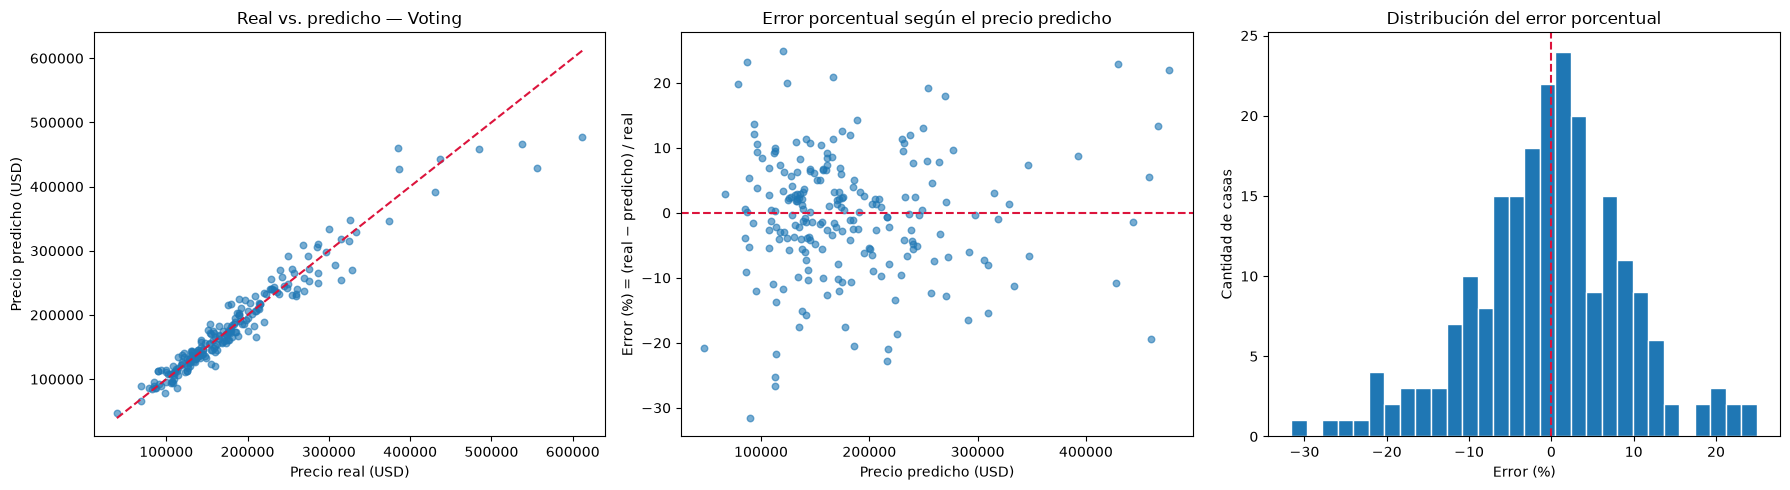

,Casas,Precio medio,RMSE_USD,MAE_USD,MAPE_%,Sesgo_USD
Tramo,,,,,,
Q1 (más baratas),55,"$106,986","$11,159","$8,785",8.7%,"$-1,864"
Q2,55,"$145,727","$12,232","$8,933",6.0%,$65
Q3,54,"$185,633","$15,630","$11,743",6.3%,$258
Q4 (más caras),55,"$295,042","$36,850","$25,128",7.7%,"$6,543"


**Las 8 predicciones con mayor error absoluto:**

,Id,Real,Predicho,Residuo,Error_%
94,100015,"$611,657","$477,154","$134,503",22.0%
34,101333,"$556,581","$429,431","$127,150",22.8%
103,101337,"$385,000","$459,753","$-74,753",-19.4%
164,100250,"$538,000","$466,419","$71,581",13.3%
136,100140,"$315,000","$254,250","$60,750",19.3%
88,100616,"$328,900","$269,886","$59,014",17.9%
62,100746,"$210,000","$166,090","$43,910",20.9%
146,100607,"$386,250","$427,727","$-41,477",-10.7%


In [25]:
best_pred = val_predictions[best_model_name]
diag = pd.DataFrame({"Real": y_val.to_numpy(), "Predicho": best_pred})
diag["Residuo"] = diag["Real"] - diag["Predicho"]
diag["Error_%"] = 100 * diag["Residuo"] / diag["Real"]
if "Id" in X_val.columns:
    diag.insert(0, "Id", X_val["Id"].to_numpy())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
lims = [diag[["Real", "Predicho"]].min().min(), diag[["Real", "Predicho"]].max().max()]
axes[0].scatter(diag["Real"], diag["Predicho"], alpha=0.6, s=22)
axes[0].plot(lims, lims, "--", color="crimson")
axes[0].set(title=f"Real vs. predicho — {best_model_name}", xlabel="Precio real (USD)", ylabel="Precio predicho (USD)")
axes[1].scatter(diag["Predicho"], diag["Error_%"], alpha=0.6, s=22)
axes[1].axhline(0, ls="--", color="crimson")
axes[1].set(title="Error porcentual según el precio predicho", xlabel="Precio predicho (USD)", ylabel="Error (%) = (real − predicho) / real")
axes[2].hist(diag["Error_%"], bins=30, edgecolor="white")
axes[2].axvline(0, ls="--", color="crimson")
axes[2].set(title="Distribución del error porcentual", xlabel="Error (%)", ylabel="Cantidad de casas")
plt.tight_layout(); plt.show()

# Error por tramo de precio (cuartiles del precio real)
diag["Tramo"] = pd.qcut(diag["Real"], 4, labels=["Q1 (más baratas)", "Q2", "Q3", "Q4 (más caras)"])
by_segment = diag.groupby("Tramo", observed=True).apply(
    lambda g: pd.Series({
        "Casas": len(g),
        "Precio medio": g["Real"].mean(),
        "RMSE_USD": np.sqrt(np.mean(g["Residuo"] ** 2)),
        "MAE_USD": g["Residuo"].abs().mean(),
        "MAPE_%": g["Error_%"].abs().mean(),
        "Sesgo_USD": g["Residuo"].mean(),
    }), include_groups=False)
display(by_segment.style.format({"Casas": "{:.0f}", "Precio medio": "${:,.0f}", "RMSE_USD": "${:,.0f}",
                                 "MAE_USD": "${:,.0f}", "MAPE_%": "{:.1f}%", "Sesgo_USD": "${:,.0f}"}))

display(Markdown("**Las 8 predicciones con mayor error absoluto:**"))
display(diag.assign(abs_err=diag["Residuo"].abs()).nlargest(8, "abs_err").drop(columns=["abs_err", "Tramo"])
        .style.format({"Real": "${:,.0f}", "Predicho": "${:,.0f}", "Residuo": "${:,.0f}", "Error_%": "{:.1f}%"}))

**Cómo leer estos gráficos y tablas:**

- **Real vs. predicho**: los puntos deberían alinearse sobre la línea punteada. Si se abren en abanico hacia la derecha, el modelo se equivoca más (en dólares) en las casas caras.
- **Error porcentual vs. precio predicho**: una nube centrada en 0 y sin forma de embudo indica que el error relativo es parejo. Una pendiente indicaría sesgo sistemático (subestima las caras o sobreestima las baratas).
- **Histograma**: debe ser aproximadamente simétrico alrededor de 0; colas largas son las casas que el modelo no pudo anticipar.
- **Tabla por tramo**: casi siempre el RMSE en dólares crece con el precio, pero el MAPE (%) se mantiene parecido o incluso es mayor en las baratas, porque un error de USD 15.000 pesa más sobre una casa de USD 90.000. `Sesgo_USD` positivo = en promedio el modelo **subestima** ese tramo.
- **Mayores errores**: suelen ser ventas anormales (`SaleCondition` ≠ Normal), casas muy singulares o con calidad extrema; son candidatas a revisarse con el equipo de negocio, no a eliminarse automáticamente.

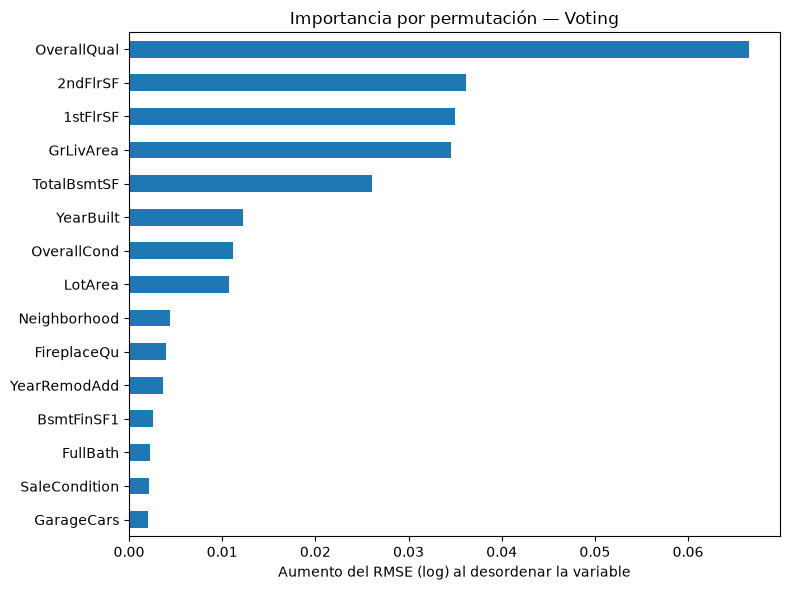

In [26]:
# Importancia por permutación sobre Validation (descriptiva: no modifica el modelo ni se usa para decidir).
perm = permutation_importance(
    fitted_models[best_model_name], X_val, np.log1p(y_val),
    scoring="neg_root_mean_squared_error", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
imp = (pd.Series(perm.importances_mean, index=X_val.columns).sort_values(ascending=False).head(15))
imp = imp[imp.index != "Id"]

fig, ax = plt.subplots(figsize=(8, 6))
imp.sort_values().plot.barh(ax=ax)
ax.set(title=f"Importancia por permutación — {best_model_name}", xlabel="Aumento del RMSE (log) al desordenar la variable")
plt.tight_layout(); plt.show()

**Cómo leer la importancia por permutación:** se desordena al azar una columna a la vez y se mide cuánto empeora el modelo. Cuanto más sube el error, más depende el modelo de esa variable. A diferencia de los coeficientes o de las importancias internas de los árboles, **mide la utilidad real para predecir datos nuevos**. Es esperable ver arriba la calidad general, la superficie habitable, el barrio y la antigüedad. Variables correlacionadas entre sí (p. ej. `GrLivArea` y `TotalSF`) se reparten la importancia, de modo que ninguna parece tan importante como realmente es el conjunto.

## 14. Verificaciones ejecutables de buenas prácticas y data leakage

Estas pruebas fallan con un `AssertionError` si algo está mal.

1. **Separación**: ningún `Id` ni vivienda duplicada entre Training y Validation (sección 2).
2. **Estadísticos aprendidos solo con Training**: se comprueba que las medianas de `LotFrontage` por barrio que guarda el transformer coinciden exactamente con las de Training, y se cuenta en cuántos barrios habrían sido distintas de haberse usado también Validation.
3. **El outlier removal no toca Validation** y se aplicó solo a Training.
4. **Prueba del target mezclado (canary)**: si se permuta al azar `SalePrice`, un pipeline sin fugas **no debería poder predecir nada** (R² de CV ≈ 0 o negativo). Si el R² fuera claramente positivo, algo del pipeline estaría filtrando información.
5. **Todo estado aprendido está dentro del `Pipeline`** y las búsquedas recibieron solo `X_train`/`y_train_log`.

In [27]:
# 2) Estadísticos aprendidos solo con Training (medianas de LotFrontage por barrio)
fe_check = AmesFeatureEngineer().fit(X_train)
train_by_hood = X_train.groupby("Neighborhood")["LotFrontage"].median()
combined = pd.concat([X_train, X_val])
combined_by_hood = combined.groupby("Neighborhood")["LotFrontage"].median()
assert np.allclose(fe_check.lotfrontage_medians_.sort_index(), train_by_hood.sort_index(), equal_nan=True)
assert np.isclose(fe_check.lotfrontage_global_median_, X_train["LotFrontage"].median())
n_diff = int((~np.isclose(train_by_hood.reindex(combined_by_hood.index), combined_by_hood, equal_nan=True)).sum())
print(f"Medianas de LotFrontage por barrio aprendidas == medianas de Training: OK")
print(f"Si se hubiera usado Training+Validation, {n_diff} de {len(combined_by_hood)} barrios tendrían otra mediana (eso sería leakage).")

# 3) Outliers: eliminados solo de Training, Validation intacta
assert len(train_clean) == len(train_df) - int(train_outliers.sum())
assert len(X_val) == len(val_df)
assert not price_outlier_mask(train_clean).any()

# 5) Estructura de los pipelines y datos usados en las búsquedas
train_median = X_train["LotFrontage"].median()
for name, s in searches.items():
    assert isinstance(s.estimator, Pipeline) and s.estimator.steps[0][0] == "fe"
    assert np.isclose(s.best_estimator_.named_steps["fe"].lotfrontage_global_median_, train_median)   # el refit vio solo Training
assert TARGET not in X_train.columns and TARGET not in X_val.columns
assert set(X_train.get("Id", [])).isdisjoint(set(X_val.get("Id", [])))

# 4) Canary: con el target permutado, el R² de CV debe ser ~0 (o negativo)
rng = np.random.RandomState(RANDOM_STATE)
y_shuffled = pd.Series(rng.permutation(y_train_log.to_numpy()), index=y_train_log.index)
canary = cross_validate(clone(searches["ElasticNet"].best_estimator_), X_train, y_shuffled, cv=cv, scoring="r2", n_jobs=-1)
canary_r2 = canary["test_score"].mean()
print(f"R² de CV con el target mezclado (esperado ≈ 0 o menor): {canary_r2:.4f}")
assert canary_r2 < 0.05, "El R² con el target permutado es demasiado alto: posible fuga de información."

print("\n✔ Todas las verificaciones pasaron: no se detecta data leakage.")

Medianas de LotFrontage por barrio aprendidas == medianas de Training: OK
Si se hubiera usado Training+Validation, 9 de 25 barrios tendrían otra mediana (eso sería leakage).
R² de CV con el target mezclado (esperado ≈ 0 o menor): -0.0944

✔ Todas las verificaciones pasaron: no se detecta data leakage.


**Cómo leer el resultado:** las medianas guardadas por el transformer coinciden exactamente con las calculadas solo con Training, aunque con Training + Validation habrían sido distintas en varios barrios: eso prueba que el transformer **no** vio Validation. El R² de CV con el target mezclado cercano a 0 (o negativo) es lo que debe pasar: sin relación real entre variables y precio, no hay nada que aprender. Si fuera, por ejemplo, 0,3, significaría que el pipeline está recibiendo información del target por otra vía.

## 15. Modelo final para producción

Una vez elegido el modelo y fijados sus hiperparámetros, es habitual **reentrenarlo con Training + Validation** para aprovechar más datos. A partir de ese reajuste **ya no se puede medir su desempeño** con esos datos, por lo que las métricas confiables son las de las secciones 11 y 12. La misma regla de outliers se aplica al conjunto combinado.

Para una estimación 100 % imparcial en el futuro, lo ideal es reservar un conjunto de **test** que nunca se use para decidir nada.

In [28]:
import joblib

full_df = pd.concat([train_df, val_df], ignore_index=True)
full_df = full_df.loc[~price_outlier_mask(full_df)].reset_index(drop=True)

final_model = clone(fitted_models[best_model_name])
final_model.fit(full_df.drop(columns=[TARGET]), np.log1p(full_df[TARGET]))

MODEL_PATH = Path("ames_final_model.joblib")
joblib.dump(final_model, MODEL_PATH)
print(f"Modelo final ({best_model_name}) reentrenado con {len(full_df)} viviendas y guardado en {MODEL_PATH.resolve()}")
print("Uso: np.expm1(joblib.load('ames_final_model.joblib').predict(nuevas_viviendas))  → precio en USD")

Modelo final (Voting) reentrenado con 1239 viviendas y guardado en /Users/luciaolivera/caso1_ia/src/ames_final_model.joblib
Uso: np.expm1(joblib.load('ames_final_model.joblib').predict(nuevas_viviendas))  → precio en USD


## 16. Conclusiones

Completá/ajustá esta sección con los números de tu corrida (las celdas de las secciones 11–13 los imprimen):

1. **Mejor modelo** (por CV) y su RMSE/MAE en Validation, en USD y en %.
2. **Mejora vs. v1**: la celda de la sección 12 calcula la diferencia contra la referencia `V1_REFERENCE`.
3. **Aporte de cada decisión**: las tablas 7.1 (Box-Cox vs. log1p vs. nada) y 7.2 (con/sin outliers) cuantifican el efecto individual.
4. **Sobreajuste**: comparar la brecha train/CV (sección 9) y CV/Validation (sección 12).
5. **Dónde se equivoca**: la tabla por tramo de precio y las mayores desviaciones (sección 13).

### Próximos experimentos sugeridos
- **Optuna** (optimización bayesiana) en lugar de búsqueda aleatoria, para Gradient Boosting y Random Forest.
- **Validación cruzada repetida** (`RepeatedKFold`) y **CV anidada** para estimar el error de todo el procedimiento de tuning de forma imparcial.
- **Target encoding** de `Neighborhood` (con `sklearn.preprocessing.TargetEncoder`, que ajusta con validación cruzada interna para no filtrar el target).
- Más modelos base en el stacking (`HistGradientBoostingRegressor`, `ExtraTreesRegressor`, SVR, KernelRidge) y un meta-modelo regularizado.
- **Intervalos de predicción** (regresión cuantílica o *conformal prediction*): para tasar no solo importa el valor puntual sino qué tan seguro es.
- Reservar un **conjunto de test** final intacto.